In [25]:
import pandas as pd
import numpy as np
import re
import nltk
import string
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import word_tokenize

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')
nltk.download('wordnet')



[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\karth\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\karth\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\karth\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\karth\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


True

In [26]:

train_df = pd.read_csv('mental_heath_unbanlanced.csv')
test_df  = pd.read_csv('mental_health_combined_test.csv')

print('Train shape:', train_df.shape)
print('Test shape :', test_df.shape)
print()
print('Train columns:', train_df.columns.tolist())
print('Test columns :', test_df.columns.tolist())

Train shape: (49612, 3)
Test shape : (992, 2)

Train columns: ['Unique_ID', 'text', 'status']
Test columns : ['text', 'status']


In [27]:

train_df.head()

,Unique_ID,text,status
0,0.0,oh my gosh,Anxiety
1,1.0,"trouble sleeping, confused mind, restless hear...",Anxiety
2,2.0,"All wrong, back off dear, forward doubt. Stay ...",Anxiety
3,3.0,I've shifted my focus to something else but I'...,Anxiety
4,4.0,"I'm restless and restless, it's been a month n...",Anxiety


In [28]:

train_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 49612 entries, 0 to 49611
Data columns (total 3 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Unique_ID  40012 non-null  float64
 1   text       49612 non-null  object 
 2   status     49612 non-null  object 
dtypes: float64(1), object(2)
memory usage: 1.1+ MB


In [29]:


print(train_df.isnull().sum())
print()

print(test_df.isnull().sum())

Unique_ID    9600
text            0
status          0
dtype: int64

text      0
status    0
dtype: int64


In [30]:

print(train_df['status'].value_counts())
print()

print(test_df['status'].value_counts())

status
Normal        18391
Depression    14506
Suicidal      11212
Anxiety        5503
Name: count, dtype: int64

status
Anxiety       248
Depression    248
Normal        248
Suicidal      248
Name: count, dtype: int64


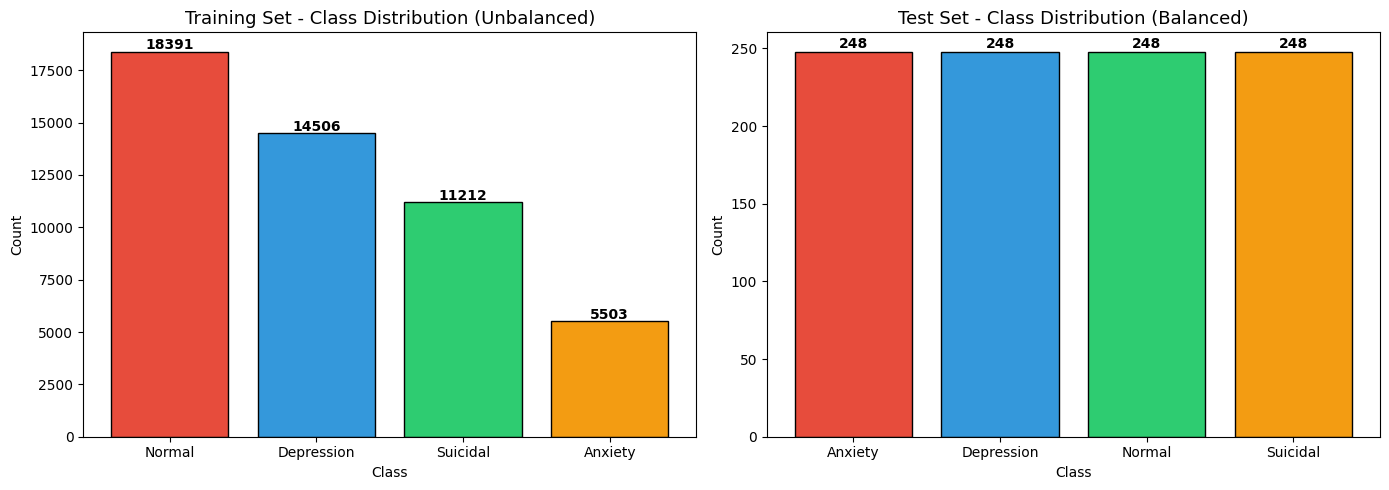

In [31]:
# Plot class distribution
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Train
train_counts = train_df['status'].value_counts()
axes[0].bar(train_counts.index, train_counts.values,
            color=['#e74c3c','#3498db','#2ecc71','#f39c12'], edgecolor='black')
axes[0].set_title('Training Set - Class Distribution (Unbalanced)', fontsize=13)
axes[0].set_xlabel('Class')
axes[0].set_ylabel('Count')
for i, v in enumerate(train_counts.values):
    axes[0].text(i, v + 100, str(v), ha='center', fontweight='bold')

# Test
test_counts = test_df['status'].value_counts()
axes[1].bar(test_counts.index, test_counts.values,
            color=['#e74c3c','#3498db','#2ecc71','#f39c12'], edgecolor='black')
axes[1].set_title('Test Set - Class Distribution (Balanced)', fontsize=13)
axes[1].set_xlabel('Class')
axes[1].set_ylabel('Count')
for i, v in enumerate(test_counts.values):
    axes[1].text(i, v + 2, str(v), ha='center', fontweight='bold')

plt.tight_layout()
plt.show()

In [32]:

train_df['text_length'] = train_df['text'].apply(len)
train_df['word_count']  = train_df['text'].apply(lambda x: len(x.split()))

print('Text length stats:')
print(train_df.groupby('status')[['text_length', 'word_count']].mean().round(2))

Text length stats:
            text_length  word_count
status                             
Anxiety          650.92      123.40
Depression       535.17      106.12
Normal           123.55       23.50
Suicidal         552.01      109.75


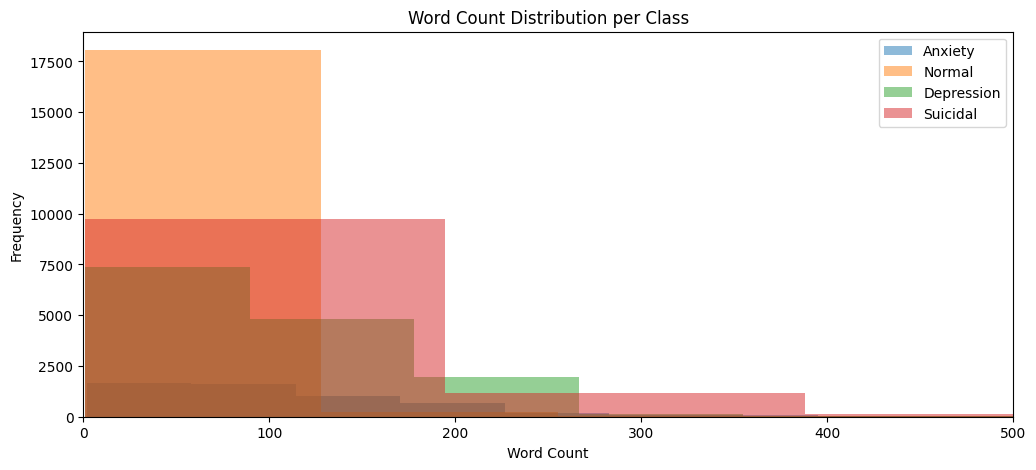

In [33]:

plt.figure(figsize=(12, 5))
for label in train_df['status'].unique():
    subset = train_df[train_df['status'] == label]['word_count']
    plt.hist(subset, bins=50, alpha=0.5, label=label)
plt.xlim(0, 500)
plt.title('Word Count Distribution per Class')
plt.xlabel('Word Count')
plt.ylabel('Frequency')
plt.legend()
plt.show()

In [34]:
stop_words  = set(stopwords.words('english'))
lemmatizer  = WordNetLemmatizer()

def preprocess_text(text):
    # Step 1: Lowercase
    text = text.lower()
    # Step 2: Remove special characters and punctuation
    text = re.sub(r'[^a-zA-Z\s]', '', text)
    # Step 3: Tokenize
    tokens = word_tokenize(text)
    # Step 4: Remove stopwords
    tokens = [word for word in tokens if word not in stop_words]
    # Step 5: Lemmatize
    tokens = [lemmatizer.lemmatize(word) for word in tokens]
    # Step 6: Join back to string
    return ' '.join(tokens)

print('Preprocessing function defined!')



Preprocessing function defined!


In [35]:
train_df

,Unique_ID,text,status,text_length,word_count
0,0.0,oh my gosh,Anxiety,10,3
1,1.0,"trouble sleeping, confused mind, restless hear...",Anxiety,64,10
2,2.0,"All wrong, back off dear, forward doubt. Stay ...",Anxiety,78,14
3,3.0,I've shifted my focus to something else but I'...,Anxiety,61,11
4,4.0,"I'm restless and restless, it's been a month n...",Anxiety,72,14
...,...,...,...,...,...
49607,NaN,i can't explain it but i know that i don't wan...,Depression,358,70
49608,NaN,nobody ever told me that when i started treatm...,Depression,800,165
49609,NaN,my wife and i split up in 2012/2013. she had a...,Depression,3378,648
49610,NaN,A close family member committed suicideI just ...,Suicidal,575,109


In [36]:

train_df['clean_text'] = train_df['text'].apply(preprocess_text)
test_df['clean_text'] = test_df['text'].apply(preprocess_text)


In [37]:

train_df[['text', 'clean_text', 'status']].head()

,text,clean_text,status
0,oh my gosh,oh gosh,Anxiety
1,"trouble sleeping, confused mind, restless hear...",trouble sleeping confused mind restless heart ...,Anxiety
2,"All wrong, back off dear, forward doubt. Stay ...",wrong back dear forward doubt stay restless re...,Anxiety
3,I've shifted my focus to something else but I'...,ive shifted focus something else im still worried,Anxiety
4,"I'm restless and restless, it's been a month n...",im restless restless month boy mean,Anxiety


In [38]:
tfidf = TfidfVectorizer(max_features=10000)
X_train_tfidf = tfidf.fit_transform(train_df['clean_text'])
X_test_tfidf  = tfidf.transform(test_df['clean_text'])
print('Train shape:', X_train_tfidf.shape)
print('Test shape :', X_test_tfidf.shape)

Train shape: (49612, 10000)
Test shape : (992, 10000)


In [39]:
le = LabelEncoder()
y_train = le.fit_transform(train_df['status'])
y_test  = le.transform(test_df['status'])
print('Labels:', dict(zip(le.classes_, le.transform(le.classes_))))

Labels: {'Anxiety': 0, 'Depression': 1, 'Normal': 2, 'Suicidal': 3}


In [40]:
# Helper function to evaluate any model
def evaluate_model(model_name, y_true, y_pred):
    print(f'=== {model_name} ===')
    print(f'Accuracy: {accuracy_score(y_true, y_pred):.4f}')
    print(classification_report(y_true, y_pred,
                                target_names=le.classes_))
    # Confusion Matrix
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(6, 4))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=le.classes_, yticklabels=le.classes_)
    plt.title(f'Confusion Matrix — {model_name}')
    plt.ylabel('Actual')
    plt.xlabel('Predicted')
    plt.tight_layout()
    plt.show()
    print()
    return accuracy_score(y_true, y_pred)

# Dictionary to store all results for final comparison
results = {}

=== Logistic Regression ===
Accuracy: 0.7087
              precision    recall  f1-score   support

     Anxiety       0.84      0.67      0.74       248
  Depression       0.55      0.60      0.57       248
      Normal       0.76      0.88      0.82       248
    Suicidal       0.72      0.69      0.70       248

    accuracy                           0.71       992
   macro avg       0.72      0.71      0.71       992
weighted avg       0.72      0.71      0.71       992



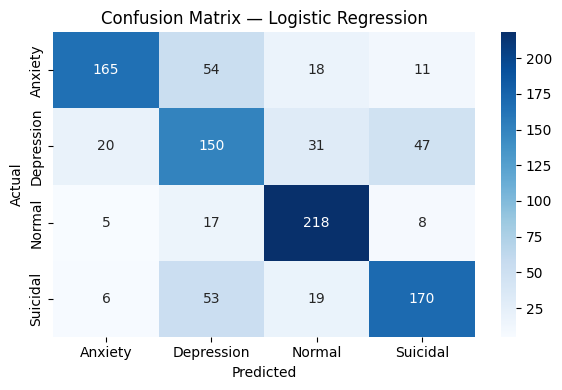

In [41]:
# ---- Model 1: Logistic Regression ----
from sklearn.linear_model import LogisticRegression

lr_model = LogisticRegression(max_iter=1000, random_state=42)
lr_model.fit(X_train_tfidf, y_train)
lr_pred = lr_model.predict(X_test_tfidf)

results['Logistic Regression'] = evaluate_model('Logistic Regression', y_test, lr_pred)

=== Naive Bayes ===
Accuracy: 0.5675
              precision    recall  f1-score   support

     Anxiety       0.95      0.21      0.34       248
  Depression       0.38      0.70      0.50       248
      Normal       0.67      0.78      0.72       248
    Suicidal       0.74      0.58      0.65       248

    accuracy                           0.57       992
   macro avg       0.69      0.57      0.55       992
weighted avg       0.69      0.57      0.55       992



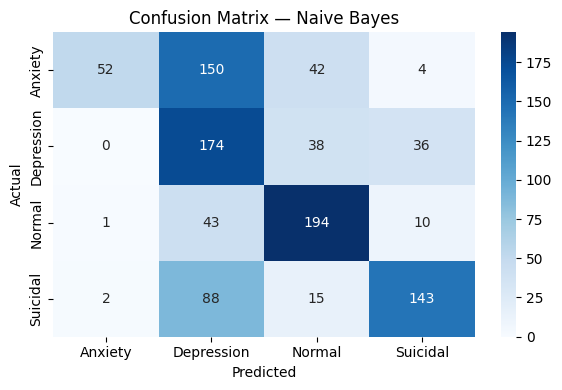

In [42]:
# ---- Model 2: Naive Bayes ----
from sklearn.naive_bayes import MultinomialNB

nb_model = MultinomialNB()
nb_model.fit(X_train_tfidf, y_train)
nb_pred = nb_model.predict(X_test_tfidf)

results['Naive Bayes'] = evaluate_model('Naive Bayes', y_test, nb_pred)

=== SVC (Linear) ===
Accuracy: 0.7349
              precision    recall  f1-score   support

     Anxiety       0.88      0.66      0.75       248
  Depression       0.63      0.60      0.61       248
      Normal       0.75      0.90      0.82       248
    Suicidal       0.72      0.78      0.75       248

    accuracy                           0.73       992
   macro avg       0.74      0.73      0.73       992
weighted avg       0.74      0.73      0.73       992



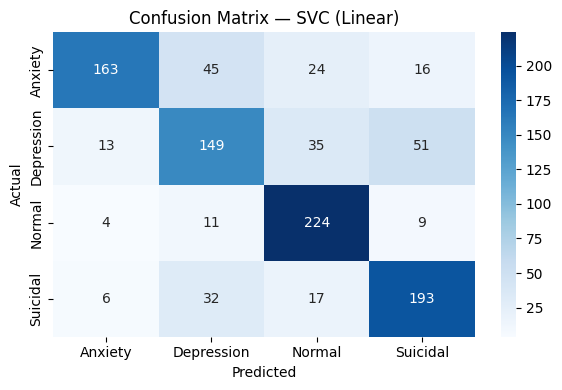

In [43]:
# ---- Model 3: SVC (Support Vector Classifier) ----
from sklearn.svm import LinearSVC

# LinearSVC is much faster than SVC on large text data
svc_model = LinearSVC(random_state=42, max_iter=2000)
svc_model.fit(X_train_tfidf, y_train)
svc_pred = svc_model.predict(X_test_tfidf)

results['SVC'] = evaluate_model('SVC (Linear)', y_test, svc_pred)

=== Random Forest ===
Accuracy: 0.8095
              precision    recall  f1-score   support

     Anxiety       0.97      0.48      0.64       248
  Depression       0.64      0.77      0.70       248
      Normal       0.89      1.00      0.94       248
    Suicidal       0.84      1.00      0.91       248

    accuracy                           0.81       992
   macro avg       0.83      0.81      0.80       992
weighted avg       0.83      0.81      0.80       992



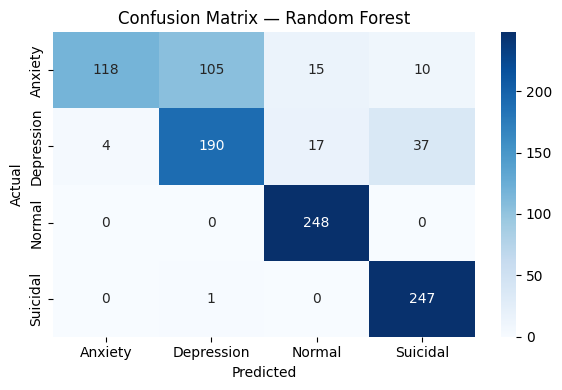

In [57]:
# ---- Model 4: Random Forest ----
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1)
rf_model.fit(X_train_tfidf, y_train)
rf_pred = rf_model.predict(X_test_tfidf)

results['Random Forest'] = evaluate_model('Random Forest', y_test, rf_pred)

In [45]:


# Convert sparse matrix to dense for Keras
tfidf = TfidfVectorizer(max_features=10000)

X_train_tfidf = tfidf.fit_transform(train_df['clean_text'])
X_test_tfidf  = tfidf.transform(test_df['clean_text'])

print('Train feature matrix shape:', X_train_tfidf.shape)
print('Test feature matrix shape :', X_test_tfidf.shape)

Train feature matrix shape: (49612, 10000)
Test feature matrix shape : (992, 10000)


In [46]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, BatchNormalization, Input
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.optimizers import Adam
import math
import numpy as np

# Improved ANN — deeper, with BatchNormalization
# BatchNormalization: normalizes each layer's output → faster learning, more stable
ann_model = Sequential([
    Input(shape=(X_train_tfidf.shape[1],)),

    Dense(512, activation='relu'),
    BatchNormalization(),    # stabilizes training after each big layer
    Dropout(0.4),

    Dense(256, activation='relu'),
    BatchNormalization(),
    Dropout(0.3),

    Dense(128, activation='relu'),
    BatchNormalization(),
    Dropout(0.3),

    Dense(64, activation='relu'),
    Dropout(0.2),

    Dense(4, activation='softmax')
])

ann_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_5 (Dense)                 │ (None, 512)            │     5,120,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 512)            │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 4)              │           260 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,296,836 (20.21 MB)

 Trainable params: 5,295,044 (20.20 MB)

 Non-trainable params: 1,792 (7.00 KB)

In [47]:
# Adam with a lower learning rate = more careful weight updates
ann_model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# EarlyStopping: stop if val_loss doesn't improve for 5 epochs
# restore_best_weights: rolls back to the best epoch automatically
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True,
    verbose=1
)

# ReduceLROnPlateau: halves learning rate when val_loss plateaus
# This helps the model escape flat regions and keep learning
reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,        # multiply LR by 0.5
    patience=3,        # wait 3 epochs before reducing
    min_lr=1e-6,
    verbose=1
)

print('Model compiled with improved settings!')

Model compiled with improved settings!


In [53]:
from sklearn.utils.class_weight import compute_class_weight

# Compute class weights
class_weights = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(y_train),
    y=y_train
)
class_weight_dict = dict(enumerate(class_weights))
print('Class weights:', class_weight_dict)

# Validation dense (test set is small — safe to convert)
X_val_dense = X_test_tfidf.toarray()

BATCH_SIZE  = 256
EPOCHS      = 30
n_train     = X_train_tfidf.shape[0]
steps_epoch = math.ceil(n_train / BATCH_SIZE)

def train_generator():
    while True:
        idx    = np.random.permutation(n_train)
        X_shuf = X_train_tfidf[idx]
        y_shuf = y_train[idx]
        for start in range(0, n_train, BATCH_SIZE):
            end     = min(start + BATCH_SIZE, n_train)
            X_batch = X_shuf[start:end].toarray()
            y_batch = y_shuf[start:end]
            # Convert class weights → per-sample weights
            # e.g. every Anxiety sample gets weight 2.25, every Normal gets 0.67
            s_batch = np.array([class_weight_dict[label] for label in y_batch])
            yield X_batch, y_batch, s_batch   # Keras accepts (X, y, sample_weight)

history = ann_model.fit(
    train_generator(),
    steps_per_epoch = steps_epoch,
    epochs          = EPOCHS,
    validation_data = (X_val_dense, y_test),
    callbacks       = [early_stop, reduce_lr],  # class_weight removed
    verbose         = 1
)

Class weights: {0: 2.253861530074505, 1: 0.8550255066868881, 2: 0.674405959436681, 3: 1.1062254727078131}
Epoch 1/30
194/194 ━━━━━━━━━━━━━━━━━━━━ 13s 69ms/step - accuracy: 0.8895 - loss: 0.2789 - val_accuracy: 0.7923 - val_loss: 0.7345 - learning_rate: 5.0000e-04
Epoch 2/30
194/194 ━━━━━━━━━━━━━━━━━━━━ 13s 66ms/step - accuracy: 0.9224 - loss: 0.1989 - val_accuracy: 0.7964 - val_loss: 0.7910 - learning_rate: 5.0000e-04
Epoch 3/30
194/194 ━━━━━━━━━━━━━━━━━━━━ 13s 65ms/step - accuracy: 0.9472 - loss: 0.1399 - val_accuracy: 0.8105 - val_loss: 0.7706 - learning_rate: 5.0000e-04
Epoch 4/30
194/194 ━━━━━━━━━━━━━━━━━━━━ 0s 64ms/step - accuracy: 0.9606 - loss: 0.1077
Epoch 4: ReduceLROnPlateau reducing learning rate to 0.0002500000118743628.
194/194 ━━━━━━━━━━━━━━━━━━━━ 13s 65ms/step - accuracy: 0.9606 - loss: 0.1077 - val_accuracy: 0.8115 - val_loss: 0.8844 - learning_rate: 5.0000e-04
Epoch 5/30
194/194 ━━━━━━━━━━━━━━━━━━━━ 13s 66ms/step - accuracy: 0.9704 - loss: 0.0826 - val_accuracy: 0.8095

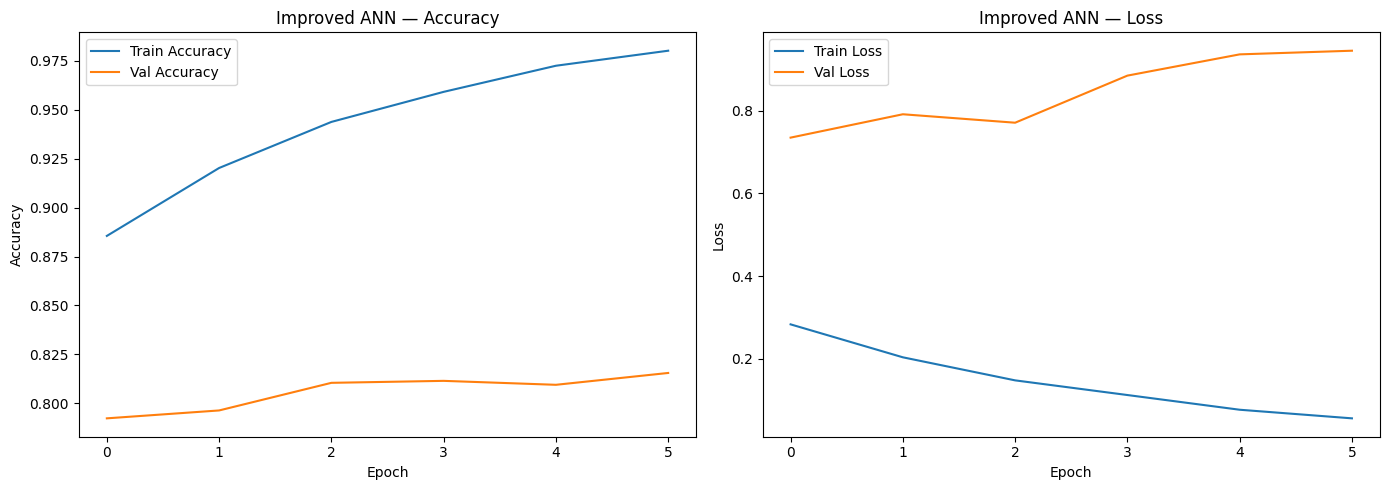

31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step
=== ANN (Improved) ===
Accuracy: 0.7923
              precision    recall  f1-score   support

     Anxiety       0.85      0.68      0.76       248
  Depression       0.71      0.56      0.63       248
      Normal       0.84      0.95      0.89       248
    Suicidal       0.76      0.97      0.85       248

    accuracy                           0.79       992
   macro avg       0.79      0.79      0.78       992
weighted avg       0.79      0.79      0.78       992



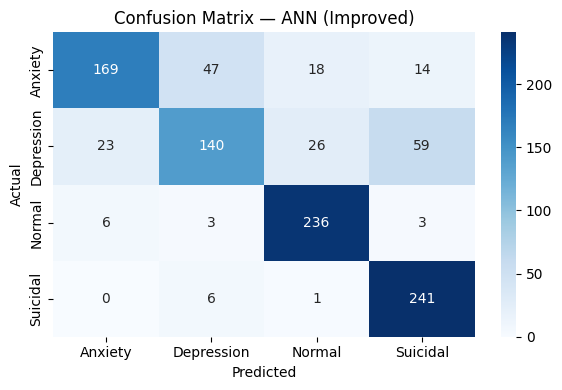

In [54]:
# Plot training curves
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(history.history['accuracy'],     label='Train Accuracy')
axes[0].plot(history.history['val_accuracy'], label='Val Accuracy')
axes[0].set_title('Improved ANN — Accuracy')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Accuracy')
axes[0].legend()

axes[1].plot(history.history['loss'],     label='Train Loss')
axes[1].plot(history.history['val_loss'], label='Val Loss')
axes[1].set_title('Improved ANN — Loss')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Loss')
axes[1].legend()

plt.tight_layout()
plt.show()

# Final evaluation
ann_pred_probs = ann_model.predict(X_val_dense)
ann_pred       = np.argmax(ann_pred_probs, axis=1)
results['ANN (Improved)'] = evaluate_model('ANN (Improved)', y_test, ann_pred)

31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step
=== ANN (Deep Learning) ===
Accuracy: 0.7923
              precision    recall  f1-score   support

     Anxiety       0.85      0.68      0.76       248
  Depression       0.71      0.56      0.63       248
      Normal       0.84      0.95      0.89       248
    Suicidal       0.76      0.97      0.85       248

    accuracy                           0.79       992
   macro avg       0.79      0.79      0.78       992
weighted avg       0.79      0.79      0.78       992



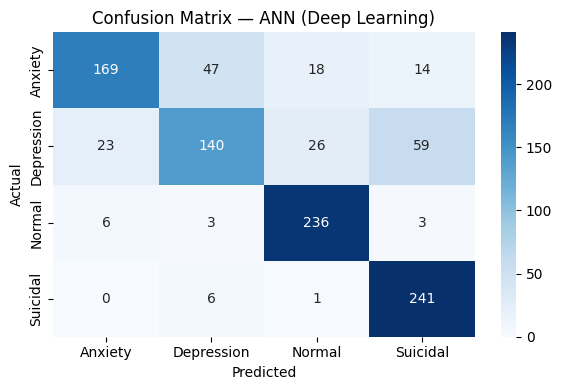

In [55]:
# Evaluate ANN — test set is small so .toarray() is safe here
ann_pred_probs = ann_model.predict(X_val_dense)
ann_pred       = np.argmax(ann_pred_probs, axis=1)

results['ANN'] = evaluate_model('ANN (Deep Learning)', y_test, ann_pred)

---
## Step 8: Model Comparison

In [56]:
# Summary table
comparison_df = pd.DataFrame({
    'Model'   : list(results.keys()),
    'Accuracy': [round(v * 100, 2) for v in results.values()]
}).sort_values('Accuracy', ascending=False).reset_index(drop=True)

print('=== Model Comparison ===')
print(comparison_df.to_string(index=False))

=== Model Comparison ===
              Model  Accuracy
      Random Forest     80.95
     ANN (Improved)     79.23
                ANN     79.23
                SVC     73.49
Logistic Regression     70.87
        Naive Bayes     56.75


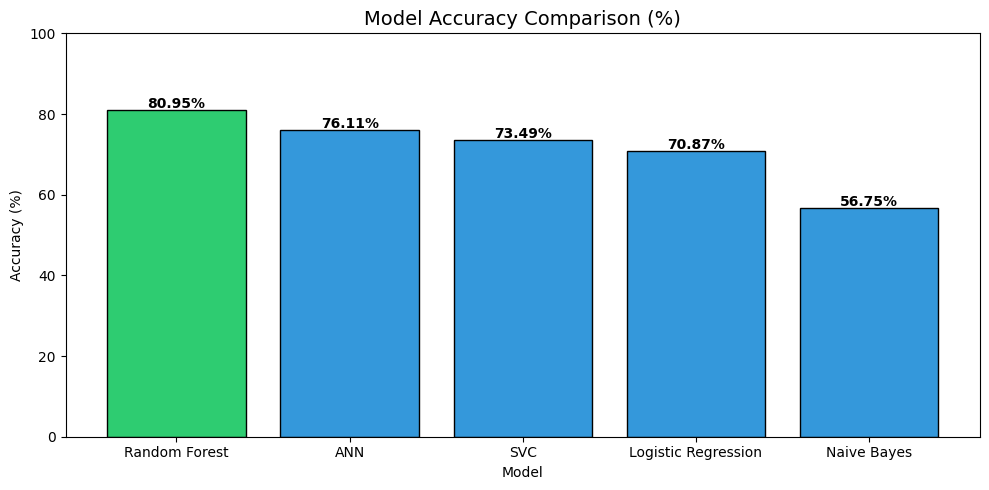

Best model: Random Forest with 80.95% accuracy


In [28]:
# Bar chart comparison
colors = ['#2ecc71' if v == comparison_df['Accuracy'].max() else '#3498db'
          for v in comparison_df['Accuracy']]

plt.figure(figsize=(10, 5))
bars = plt.bar(comparison_df['Model'], comparison_df['Accuracy'],
               color=colors, edgecolor='black')
plt.title('Model Accuracy Comparison (%)', fontsize=14)
plt.xlabel('Model')
plt.ylabel('Accuracy (%)')
plt.ylim(0, 100)
for bar, val in zip(bars, comparison_df['Accuracy']):
    plt.text(bar.get_x() + bar.get_width()/2,
             bar.get_height() + 0.5, f'{val}%', ha='center', fontweight='bold')
plt.tight_layout()
plt.show()
print(f"Best model: {comparison_df.iloc[0]['Model']} with {comparison_df.iloc[0]['Accuracy']}% accuracy")

In [29]:
def preprocess_input(text):
    """Same preprocessing pipeline used during training"""
    text = text.lower()
    text = re.sub(r'[^a-zA-Z\s]', '', text)
    tokens = word_tokenize(text)
    tokens = [word for word in tokens if word not in stop_words]
    tokens = [lemmatizer.lemmatize(word) for word in tokens]
    return ' '.join(tokens)

def predict_ml(text, model=lr_model, model_name='Logistic Regression'):
    """Predict using a classical ML model"""
    cleaned  = preprocess_input(text)
    vec      = tfidf.transform([cleaned])
    pred     = model.predict(vec)[0]
    label    = le.inverse_transform([pred])[0]
    print(f'[{model_name}] Predicted: {label}')
    return label

def predict_ann(text):
    """Predict using the ANN model"""
    cleaned  = preprocess_input(text)
    vec      = tfidf.transform([cleaned]).toarray()
    probs    = ann_model.predict(vec, verbose=0)[0]
    pred     = np.argmax(probs)
    label    = le.inverse_transform([pred])[0]
    print(f'[ANN] Predicted: {label}')
    print(f'      Probabilities: { {le.classes_[i]: round(float(probs[i])*100, 1) for i in range(4)} }')
    return label

print('Prediction functions ready!')

Prediction functions ready!


In [30]:
# Test with sample texts
samples = [
    "I feel so hopeless, I don't see a reason to continue living anymore.",
    "I have been feeling really sad and empty for weeks, nothing makes me happy.",
    "My heart is racing, I'm constantly worried and can't stop panicking.",
    "I had a great day today, went for a walk and met some friends!"
]

for sample in samples:
    print(f'\nText: "{sample[:60]}..."')
    predict_ml(sample, lr_model, 'Logistic Regression')
    predict_ann(sample)
    print('-' * 60)


Text: "I feel so hopeless, I don't see a reason to continue living ..."
[Logistic Regression] Predicted: Suicidal
[ANN] Predicted: Suicidal
      Probabilities: {'Anxiety': 0.3, 'Depression': 25.1, 'Normal': 0.9, 'Suicidal': 73.7}
------------------------------------------------------------

Text: "I have been feeling really sad and empty for weeks, nothing ..."
[Logistic Regression] Predicted: Depression
[ANN] Predicted: Depression
      Probabilities: {'Anxiety': 0.1, 'Depression': 79.9, 'Normal': 3.9, 'Suicidal': 16.1}
------------------------------------------------------------

Text: "My heart is racing, I'm constantly worried and can't stop pa..."
[Logistic Regression] Predicted: Anxiety
[ANN] Predicted: Anxiety
      Probabilities: {'Anxiety': 93.1, 'Depression': 4.1, 'Normal': 2.1, 'Suicidal': 0.8}
------------------------------------------------------------

Text: "I had a great day today, went for a walk and met some friend..."
[Logistic Regression] Predicted: Normal
[ANN] P

In [ ]:
# Interactive prediction — type your own text
user_text = input('Enter a text to classify: ')
print()
predict_ml(user_text, lr_model, 'Logistic Regression')
predict_ml(user_text, svc_model, 'SVC')
predict_ann(user_text)

In [ ]:
import pickle

# Save TF-IDF vectorizer
with open('tfidf_mental_health.pkl', 'wb') as f:
    pickle.dump(tfidf, f)

# Save Label Encoder
with open('label_encoder_mental_health.pkl', 'wb') as f:
    pickle.dump(le, f)

# Save best ML model (Logistic Regression)
with open('lr_mental_health.pkl', 'wb') as f:
    pickle.dump(lr_model, f)

# Save ANN model
ann_model.save('ann_mental_health.h5')

print('All models saved successfully!')